In [24]:
import gymnasium as gym
import torch
import torch.nn as nn
import numpy as np


# Red DQN simple - misma arquitectura que usamos en S7
class DQN(nn.Module):
    def __init__(self, state_dim=4, n_actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, n_actions),
        )

    def forward(self, x):
        return self.net(x)


# Cargar pesos pre-entrenados (archivo generado en el lab 7 )
expert_dqn = DQN()
expert_dqn.load_state_dict(torch.load("experto_cartpole.pth"))
expert_dqn.eval()

DQN(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [25]:
def expert_policy(obs):
    """Agente DQN experto: elige la accion con Q mas alto."""
    with torch.no_grad():
        obs_t = torch.FloatTensor(obs).unsqueeze(0)
        q_vals = expert_dqn(obs_t)
        return q_vals.argmax().item()  # accion greedy


def collect_demos(env, n_episodes=50):
    demos = []  # lista de (obs, action)
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=ep)
        while True:
            action = expert_policy(obs)  # experto decide
            demos.append((obs.copy(), action))  # guardar par
            obs, _, done, trunc, _ = env.step(action)
            if done or trunc:
                break
    return demos  # [(obs_0,a_0), (obs_1,a_1), ...]


env = gym.make("CartPole-v1")
demos = collect_demos(env, n_episodes=50)
print(f"Total pares: {len(demos)}")  # ~25,000 pares
print(f"Obs shape: {demos[0][0].shape}")  # (4,)

Total pares: 25000
Obs shape: (4,)


In [26]:
class BCPolicy(nn.Module):
    def __init__(self, state_dim=4, n_actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, n_actions),
        )  # output = logits (sin softmax)

    def forward(self, x):
        return self.net(x)  # logits

    def predict(self, obs):
        with torch.no_grad():
            obs_t = torch.FloatTensor(obs).unsqueeze(0)
            return self.forward(obs_t).argmax().item()

In [27]:
# Preparar tensores desde la lista de demos
states = torch.from_numpy(np.stack([d[0] for d in demos])).float()
actions = torch.LongTensor([d[1] for d in demos])

# Modelo, optimizador y loss
bc_policy = BCPolicy(state_dim=4, n_actions=2)
optimizer = torch.optim.Adam(bc_policy.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

train_losses = []
N_EPOCHS = 50

for epoch in range(1, N_EPOCHS + 1):
    bc_policy.train()
    optimizer.zero_grad()
    logits = bc_policy(states)
    loss = loss_fn(logits, actions)
    loss.backward()
    optimizer.step()

    bc_policy.eval()
    with torch.no_grad():
        epoch_loss = loss_fn(bc_policy(states), actions).item()
    train_losses.append(epoch_loss)

    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch {epoch:3d}: loss = {epoch_loss:.4f}")

Epoch   1: loss = 0.6908
Epoch  10: loss = 0.6283
Epoch  20: loss = 0.5498
Epoch  30: loss = 0.4649
Epoch  40: loss = 0.4047
Epoch  50: loss = 0.3790


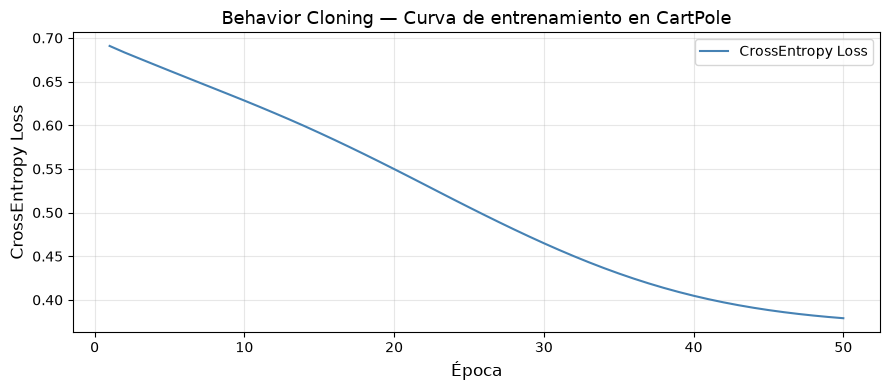

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    color="steelblue",
    linewidth=1.5,
    label="CrossEntropy Loss",
)
plt.xlabel("Época", fontsize=12)
plt.ylabel("CrossEntropy Loss", fontsize=12)
plt.title("Behavior Cloning — Curva de entrenamiento en CartPole", fontsize=13)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**La curva de entrenamientobaja pero, ¿esogarantizaqueelagenteBC funcionarábien enelentorno? ¿Qué podría salir mal aunquela loss sea baja?**

> Lorem


In [29]:
def evaluate_policy(policy_fn, env, n_episodes=50):
    rewards = []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=1000 + ep)  # seeds distintos al training
        total, done = 0, False
        while not done:
            action = policy_fn(obs)
            obs, r, done, trunc, _ = env.step(action)
            total += r
            done = done or trunc
        rewards.append(total)
    return rewards


env = gym.make("CartPole-v1")
r_expert = evaluate_policy(expert_policy, env)
r_bc = evaluate_policy(bc_policy.predict, env)

print(f"Experto — promedio: {np.mean(r_expert):.1f}  std: {np.std(r_expert):.1f}")
print(f"BC      — promedio: {np.mean(r_bc):.1f}  std: {np.std(r_bc):.1f}")

Experto — promedio: 500.0  std: 0.0
BC      — promedio: 143.4  std: 72.1


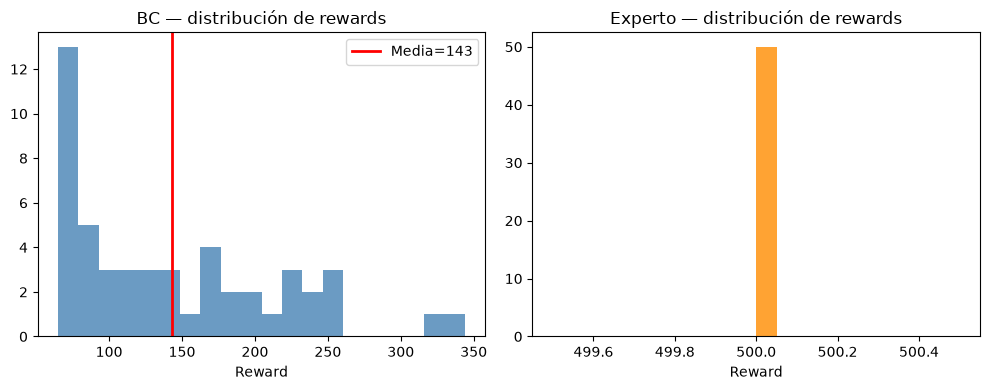

In [30]:
# Ver la distribución de longitudes de episodio
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(r_bc, bins=20, color="steelblue", alpha=0.8)
plt.axvline(np.mean(r_bc), color="red", lw=2, label=f"Media={np.mean(r_bc):.0f}")
plt.xlabel("Reward")
plt.title("BC — distribución de rewards")
plt.legend()
plt.subplot(1, 2, 2)
plt.hist(r_expert, bins=20, color="darkorange", alpha=0.8)
plt.xlabel("Reward")
plt.title("Experto — distribución de rewards")
plt.tight_layout()
plt.show()

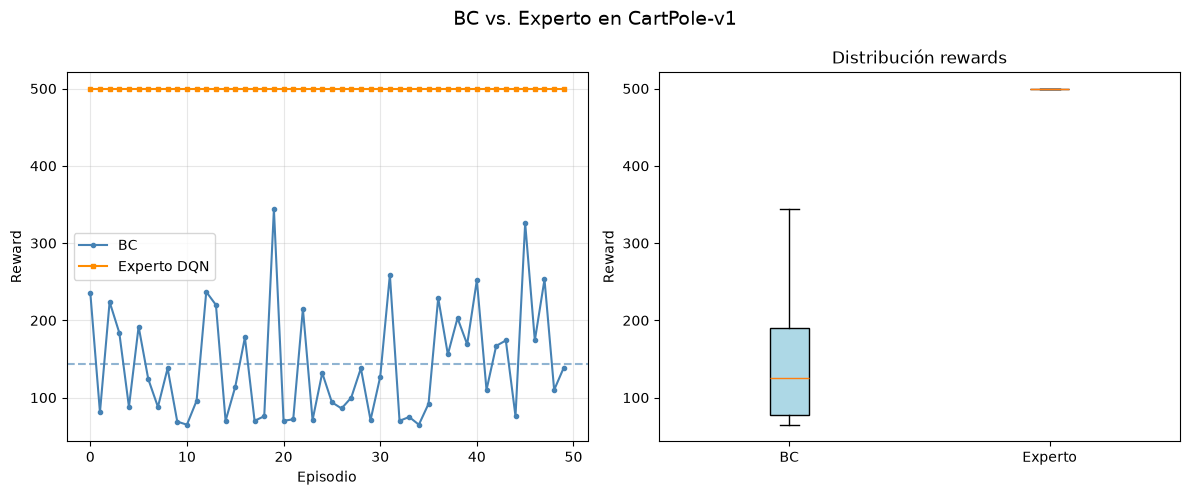

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel izq: curvas de reward
ax = axes[0]
ax.plot(r_bc, "o-", color="steelblue", lw=1.5, ms=3, label="BC")
ax.plot(r_expert, "s-", color="darkorange", lw=1.5, ms=3, label="Experto DQN")
ax.axhline(np.mean(r_bc), color="steelblue", ls="--", alpha=0.6)
ax.set_xlabel("Episodio")
ax.set_ylabel("Reward")
ax.legend()
ax.grid(alpha=0.3)

# Panel der: boxplot
axes[1].boxplot(
    [r_bc, r_expert],
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["BC", "Experto"])
axes[1].set_ylabel("Reward")
axes[1].set_title("Distribución rewards")

plt.suptitle("BC vs. Experto en CartPole-v1", fontsize=14)
plt.tight_layout()
plt.show()

## T5 · Análisis

### 1. Cota del costo extra

El ejemplo del PDF reporta un reward promedio de BC de aproximadamente 180. Según la cota $O(\epsilon T^2)$, ¿cuál sería la cota teórica de costo extra con $T=200$ y $\epsilon=0.05$? ¿Cómo se compara con la brecha observada en esta corrida al mismo horizonte?

**Respuesta.** Con $T=200$ y $\epsilon=0.05$, la cota del ejercicio es $0.05 \times 200 \times 201 / 2 = 1005$. Al limitar ambas políticas a 200 pasos, la brecha media observada fue de **68.58 puntos**. La cota es muy holgada: incluso la máxima brecha posible de reward a ese horizonte es 200, porque CartPole da un punto por paso.


In [ ]:
horizon = 200
epsilon = 0.05
extra_cost_bound = epsilon * sum(range(1, horizon + 1))

# En CartPole se suma un punto por paso. Recortar al horizonte común.
expert_reward_at_horizon = np.minimum(r_expert, horizon)
bc_reward_at_horizon = np.minimum(r_bc, horizon)
observed_gap = np.mean(expert_reward_at_horizon - bc_reward_at_horizon)

print(f"Cota teórica de costo extra: {extra_cost_bound:.2f}")
print(f"Brecha media de reward hasta T={horizon}: {observed_gap:.2f}")

Cota teórica de costo extra: 1005.00
Brecha media de reward hasta T=200: 68.58


### 2. Variabilidad y robustez

En el ejemplo del PDF, el experto tiene una desviación estándar de reward de aproximadamente 3 y BC de aproximadamente 142. ¿Por qué pueden diferir? ¿Qué implican la dispersión y los episodios cortos de esta corrida para la robustez de cada política?

**Respuesta.** El experto llegó a 500 en los 50 episodios (desviación estándar de **0.0**). BC promedió **143.4**, con una desviación de **72.1**, un rango de **65 a 344** y **38 de 50** episodios por debajo de 200. El experto fue más consistente frente a las condiciones iniciales evaluadas. La variabilidad de BC es compatible con el cambio de distribución: un error puede llevarlo a estados poco representados en las demostraciones y hacer que se acumulen más errores. Los rewards muestran esa diferencia de robustez, aunque por sí solos no identifican qué estados causaron las caídas.


In [33]:
short_episode_threshold = 200

# Los rewards ya fueron evaluados con las mismas semillas para ambas políticas.
for name, rewards in [("Experto", r_expert), ("BC", r_bc)]:
    rewards = np.asarray(rewards)
    short_episodes = np.count_nonzero(rewards < short_episode_threshold)
    print(
        f"{name}: media={rewards.mean():.1f}, std={rewards.std():.1f}, "
        f"mínimo={rewards.min():.0f}, máximo={rewards.max():.0f}, "
        f"episodios por debajo de {short_episode_threshold}: "
        f"{short_episodes}/{len(rewards)}"
    )

Experto: media=500.0, std=0.0, mínimo=500, máximo=500, episodios por debajo de 200: 0/50
BC: media=143.4, std=72.1, mínimo=65, máximo=344, episodios por debajo de 200: 38/50


### 3. Duplicar las demostraciones

Si se usan 100 episodios del mismo experto en lugar de 50, ¿mejora mucho BC? ¿Por qué sí o por qué no? Compara ambas políticas con el mismo presupuesto de entrenamiento y las mismas semillas de evaluación.

**Respuesta.** En esta comparación, duplicar las demostraciones de 25 000 a 50 000 pares apenas cambió el reward medio (**101.8 → 101.6**). La desviación estándar bajó de **51.5 a 50.1** y los episodios por debajo de 200 pasaron de **45 a 46 de 50**. Ambas políticas usaron la misma inicialización, 50 actualizaciones de Adam y las mismas semillas de evaluación. Más trayectorias del mismo experto pueden ampliar la cobertura de sus propios estados, pero no garantizan ejemplos de los estados a los que BC llega al equivocarse. En esta corrida, duplicar los datos no mejoró el rendimiento.


In [34]:
def train_bc_for_comparison(demonstrations):
    demo_states = torch.from_numpy(np.stack([obs for obs, _ in demonstrations])).float()
    demo_actions = torch.LongTensor([action for _, action in demonstrations])

    # Misma inicialización en ambas condiciones, sin cambiar el RNG del notebook.
    with torch.random.fork_rng(devices=[]):
        torch.random.default_generator.manual_seed(13)
        policy = BCPolicy(state_dim=4, n_actions=2)

    comparison_optimizer = torch.optim.Adam(policy.parameters(), lr=1e-3)
    policy.train()
    for _ in range(N_EPOCHS):
        comparison_optimizer.zero_grad()
        loss = loss_fn(policy(demo_states), demo_actions)
        loss.backward()
        comparison_optimizer.step()
    policy.eval()
    return policy


comparison_env = gym.make("CartPole-v1")
try:
    # collect_demos usa semillas 0 a 99. Las primeras 50 coinciden con demos.
    demos_100 = collect_demos(comparison_env, n_episodes=100)
    for n_episodes, dataset in [(50, demos), (100, demos_100)]:
        comparison_policy = train_bc_for_comparison(dataset)
        rewards = np.asarray(evaluate_policy(comparison_policy.predict, comparison_env))
        short_episodes = np.count_nonzero(rewards < 200)
        print(
            f"{n_episodes} episodios de demos ({len(dataset)} pares): "
            f"media={rewards.mean():.1f}, std={rewards.std():.1f}, "
            f"episodios por debajo de 200: {short_episodes}/{len(rewards)}"
        )
finally:
    comparison_env.close()

50 episodios de demos (25000 pares): media=101.8, std=51.5, episodios por debajo de 200: 45/50
100 episodios de demos (50000 pares): media=101.6, std=50.1, episodios por debajo de 200: 46/50
